# Kats API: forecasting a toy series with ARIMA, Prophet, and MLAR

- This notebook explores the Kats forecasting API on one small synthetic series
  (a trend, a repeating pattern, and noise), so every result can be checked by
  eye
- The pedagogical arc:
  - `TimeSeriesData`: the one input type every Kats model accepts
  - Params and Model objects: configure, `fit()`, `predict()`
  - The same pattern for ARIMA and Prophet, and where the two differ
  - A minimal end-to-end workflow with the wrappers in `kats_utils.py`
  - `MLARModel`: a model that does not follow the pattern

In [1]:
%load_ext autoreload
%autoreload 2

import logging

# Kats warns at import time about optional packages (torch, ax-platform) that
# this notebook does not use. Raise the log level before importing it.
logging.getLogger().setLevel(logging.ERROR)
logging.getLogger("prophet.plot").setLevel(logging.CRITICAL)

import pandas as pd
from kats.consts import TimeSeriesData
from kats.models.arima import ARIMAModel, ARIMAParams
from kats.models.ml_ar import MLARModel, MLARParams
from kats.models.prophet import ProphetModel, ProphetParams

In [2]:
import helpers.hintrospection as hintros
import helpers.hnotebook as hnotebook

import kats_utils as utils

# Initialize notebook configuration and logging.
hnotebook.config_notebook()
_LOG = logging.getLogger(__name__)
utils.init_loggers(_LOG)

# Convert `display` into `print()` when running outside IPython.
try:
    from IPython.display import display
except ImportError:
    display = print  # type: ignore

INFO  > /home/claude/sim311/lib/python3.11/site-packages/ipykernel_launcher.py -f /tmp/tmpyvs7uu03.json --HistoryManager.hist_file=:memory:


## Library Overview

- **What problem it solves**: Kats (Kit to Analyze Time Series, from Meta) puts
  several forecasting models behind one small set of classes, so trying a second
  model costs a few lines instead of a new library
- **Key abstraction**: `TimeSeriesData` wraps a time column and a value column,
  and every model takes one as input
- **Mental model**: a `Params` object holds the settings, a `Model` object holds
  the data and the params, `fit()` trains it in place, and `predict()` returns a
  `DataFrame`

| Object | Description | Comments |
|--------|-------------|----------|
| `TimeSeriesData(df)` | Time series container | Columns `time` and `value` |
| `ARIMAParams(p, d, q)` | Settings of an ARIMA model | Plain attributes |
| `ARIMAModel(data, params)` | ARIMA forecaster | Wraps a `statsmodels` model |
| `ProphetParams(...)` | Settings of a Prophet model | Many optional arguments |
| `ProphetModel(data, params)` | Prophet forecaster | Wraps `prophet.Prophet` |
| `model.fit()` | Train in place | Returns `None` |
| `model.predict(steps, freq)` | Forecast ahead | Frame with `time`, `fcst`, `fcst_lower`, `fcst_upper` |
| `MLARModel(params)` | Gradient-boosted autoregression | Uses `train()`, not `fit()` |

- **Key classes**:
  - `TimeSeriesData`: the input container
  - `ARIMAModel`: the classical statistical baseline
  - `ProphetModel`: a trend plus seasonality model
  - `MLARModel`: a LightGBM model that can use extra features

# Part 1: `TimeSeriesData`, the input type

## Cell 1.1: Build a toy series

- The series has 80 business days with an upward trend, a repeating pattern, and
  noise
- Business days (`"B"`, Monday to Friday) are the frequency used for stock
  prices in the example notebook

In [3]:
# Build a toy series indexed by business day.
series = utils.make_synthetic_series(num_periods=80, freq="B")
display(series.head(3))
# Outcome: values near 50 that start to climb, indexed from 2020-01-01.

2020-01-01    50.125730
2020-01-02    52.313390
2020-01-03    53.765206
Freq: B, Name: value, dtype: float64

## Cell 1.2: Plot the toy series

**Goal**
- See the trend and the repeating pattern that the models have to capture

**Description**
- Panels
  - `Toy series`: the 80 values as a line over time

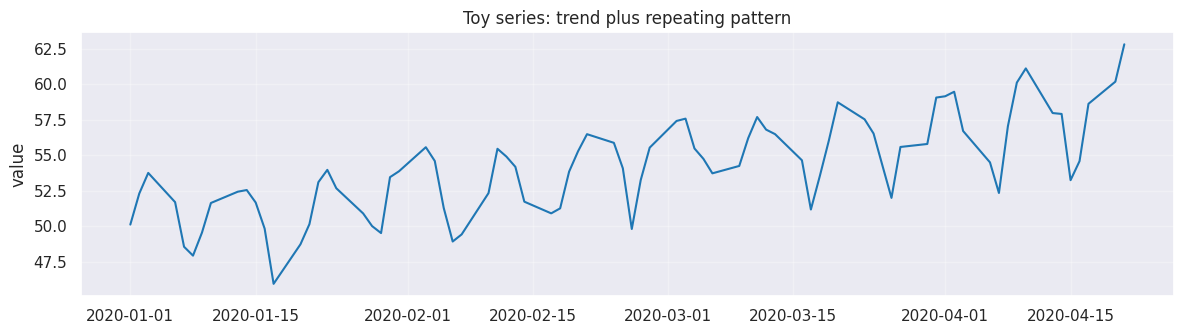

In [4]:
# Plot the series.
utils.plot_series(series, title="Toy series: trend plus repeating pattern")

**Guided usage**
- Compare the line at the start and at the end
  - Observe the level rising by about 8 over the 80 days, from the trend
- Look at a few neighbouring days
  - Observe the small up and down swings, from the repeating pattern and noise

**Implementation** `plot_series(series, *, title="", figsize=(12, 3.5))`
- Draws the values against the index as one line
- Adds the title, a label for the y axis, and a light grid

In [5]:
# Link the function to its source and list its interface.
hintros.print_obj_info(utils.plot_series)

- `plot_series(series: pandas.core.series.Series, *, title: str = '', figsize: Tuple[float, float] = (12, 3.5)) -> None`  
  Plot a time series as a line.

https://github.com/madhur2003/msml610_fall2026_kats_stock_price_forecasting/blob/UmdTask851_MSML610_Fall2026_Kats_Stock_Price_Forecasting/class_project/msml610/Fall2026/projects/UmdTask851_MSML610_Fall2026_Kats_Stock_Price_Forecasting/kats_utils.py#L718


## Cell 1.3: Minimal construction

- `TimeSeriesData` takes a `DataFrame` with a `time` column and a `value` column

In [6]:
# Put the series in the layout that Kats expects.
df = pd.DataFrame({"time": series.index, "value": series.to_numpy()})
# Wrap the frame in a Kats container.
ts = TimeSeriesData(df)
print("type(ts)=", type(ts))
# Outcome: a `kats.consts.TimeSeriesData` object.

type(ts)= <class 'kats.consts.TimeSeriesData'>


## Cell 1.4: Inspect the object

In [7]:
# Count the observations.
print("len(ts)=", len(ts))
# Outcome: 80, one per business day.

len(ts)= 80


In [8]:
# The time and the values are two separate pandas Series.
print("type(ts.time)=", type(ts.time), "dtype:", ts.time.dtype)
print("type(ts.value)=", type(ts.value), "dtype:", ts.value.dtype)
# Outcome: `time` is `datetime64[ns]` and `value` is `float64`.

type(ts.time)= <class 'pandas.core.series.Series'> dtype: datetime64[ns]
type(ts.value)= <class 'pandas.core.series.Series'> dtype: float64


In [9]:
# Get the data back as a DataFrame.
display(ts.to_dataframe().head(3))
# Outcome: the same two columns that went in, `time` and `value`.

,time,value
0,2020-01-01,50.125730
1,2020-01-02,52.313390
2,2020-01-03,53.765206


## Cell 1.5: Construct from separate time and value

- The other way to build it is with `time=` and `value=` arguments
- The `value` argument can be a named Series, and the name becomes the column
  name

In [10]:
# Build the same container from the index and the Series, with no DataFrame.
ts_kw = TimeSeriesData(time=series.index, value=series)
print("ts_kw.value.name=", ts_kw.value.name)
print("len(ts_kw)=", len(ts_kw))
# Outcome: the name `value` comes from `series.name`, and the length is 80.

ts_kw.value.name= value
len(ts_kw)= 80


## Cell 1.6: Public interface

In [11]:
# Link the class to its source on GitHub, and list its public interface.
utils.print_kats_obj_info(TimeSeriesData)
# Outcome: methods such as `to_dataframe`, `interpolate`, `plot`, `extend`.

**TimeSeriesData**
- `convert_timezone(self, tz: 'str') -> 'None'`
- `exclude(self, start: 'pd.Timestamp', end: 'pd.Timestamp') -> 'TimeSeriesData'`: Exclude data between start and end.
- `extend(self, other: 'object', validate: 'bool' = True) -> 'None'`: Extends :class:`TimeSeriesData` with another :class:`TimeSeriesData`...
- `freq_to_timedelta(self) -> 'pd.Timedelta'`: Returns a `pandas.Timedelta` representation of the...
- `infer_freq_robust(self) -> 'pd.Timedelta'`: This method is a more robust way to infer the frequency of the time...
- `interpolate(self, freq: 'Optional[Union[str, pd.Timedelta]]' = None, base: 'int' = 0, origin: 'pd.Timestamp | str' = 'start_day', method: 'str' = 'linear', remove_duplicate_time: 'bool' = False, **kwargs: 'Any') -> 'TimeSeriesData'`: Interpolate missing date if `time` doesn't have constant frequency.
- `is_data_missing(self) -> 'bool'`: Checks if data is missing from the time series.
- `is_empty(self) -> 'bool'`: Checks if the :class:`TimeSeriesData` is empty.
- `is_timezone_aware(self) -> 'bool'`
- `is_univariate(self) -> 'bool'`: Returns whether the :class:`TimeSeriesData` is univariate.
- `plot(self, cols: 'Optional[List[str]]' = None, ax: 'Optional[plt.Axes]' = None, grid: 'bool' = True, figsize: 'Optional[FigSize]' = None, plot_kwargs: 'Optional[Dict[str, Any]]' = None, grid_kwargs: 'Optional[Dict[str, Any]]' = None) -> 'plt.Axes'`: Plots the time series.
- `set_timezone(self, tz: 'str', tz_ambiguous: "Literal['raise', 'infer', 'NaT']" = 'raise', tz_nonexistent: "Literal['NaT', 'raise', 'shift_backward', 'shift_forward']" = 'raise', sort_by_time: 'bool' = True) -> 'None'`
- `time_to_index(self) -> 'pd.DatetimeIndex'`: Utility function converting the time in the :class:`TimeSeriesData`...
- `to_array(self) -> 'npt.NDArray'`: Converts the :class:`TimeSeriesData` object to a `numpy.ndarray`.
- `to_dataframe(self, standard_time_col_name: 'bool' = False) -> 'pd.DataFrame'`: Converts the :class:`TimeSeriesData` object into a `pandas.DataFrame`.
- `tz(self) -> 'Union[datetime.tzinfo, dateutil.tz.tz.tzfile, None]'`: Returns the timezone of the :class:`TimeSeriesData`.
- `validate_data(self, validate_frequency: 'bool', validate_dimension: 'bool') -> 'None'`: Validates the time series for correctness (on both frequency and...

https://github.com/facebookresearch/Kats/blob/25e6162ae7733fe7ce36ff05fe2844398bf92f93/kats/consts.py#L153


## Cell 1.7: Slice into a training set and a test set

- Slicing a `TimeSeriesData` returns another `TimeSeriesData`
- Forecasting always splits by time, never at random, so the model never sees the
  future

In [12]:
# Keep the first 70 days for training and the last 10 days for testing.
train_ts = ts[:70]
test_ts = ts[70:]
print("type(train_ts)=", type(train_ts))
print("len(train_ts)=", len(train_ts), "len(test_ts)=", len(test_ts))
print("last train day=", train_ts.time.iloc[-1].date())
print("first test day=", test_ts.time.iloc[0].date())
# Outcome: 70 and 10 points, and the test set starts the day after the training set.

type(train_ts)= <class 'kats.consts.TimeSeriesData'>
len(train_ts)= 70 len(test_ts)= 10
last train day= 2020-04-07
first test day= 2020-04-08


# Part 2: ARIMA, the params, model, `fit()`, `predict()` pattern

## Cell 2.1: Params hold the settings

- `ARIMAParams(p, d, q)` only stores three integers, nothing is trained yet
  - `p`: number of past values used (autoregressive part)
  - `d`: number of times the series is differenced to remove the trend
  - `q`: number of past errors used (moving-average part)

In [13]:
# Choose a small model: one lag, one difference, no moving-average term.
arima_params = ARIMAParams(p=1, d=1, q=0)
print("type(arima_params)=", type(arima_params))
print("p, d, q=", arima_params.p, arima_params.d, arima_params.q)
# Outcome: the object just echoes back the three numbers.

type(arima_params)= <class 'kats.models.arima.ARIMAParams'>
p, d, q= 1 1 0


## Cell 2.2: A model holds the data and the params

In [14]:
# Combine the training data and the params in a model.
arima_model = ARIMAModel(train_ts, arima_params)
print("type(arima_model)=", type(arima_model))
print("arima_model.model=", arima_model.model)
# Outcome: the `model` attribute is `None`, because nothing has been trained yet.

type(arima_model)= <class 'kats.models.arima.ARIMAModel'>
arima_model.model= None


## Cell 2.3: Public interface

In [15]:
# Link the class to its source on GitHub, and list its public interface.
utils.print_kats_obj_info(ARIMAModel)
# Outcome: `fit`, `predict`, `plot`, and `get_parameter_search_space`.

**ARIMAModel**
- `fit(self, trend: str = 'n', start_params: Optional[numpy.ndarray[Any, numpy.dtype[+_ScalarType_co]]] = None, transformed: bool = True, includes_fixed: bool = False, method: Optional[str] = None, method_kwargs: Optional[Dict[str, Any]] = None, gls: Optional[bool] = None, gls_kwargs: Optional[Dict[str, Any]] = None, cov_type: Optional[str] = None, cov_kwds: Optional[Dict[str, Any]] = None, **kwargs: Any) -> None`: Fit ARIMA model with given parameters
- `get_parameter_search_space() -> List[Dict[str, Any]]`: Get default ARIMA parameter search space.
- `plot(self, ax: Optional[matplotlib.axes._axes.Axes] = None, figsize: Optional[Tuple[int, int]] = None, **kwargs: Any) -> matplotlib.axes._axes.Axes`: Plot method for forecasting models
- `predict(self, steps: int, include_history: bool = False, exog: Optional[numpy.ndarray[Any, numpy.dtype[+_ScalarType_co]]] = None, alpha: float = 0.05, **kwargs: Any) -> pandas.core.frame.DataFrame`: Predict with fitted ARIMA model
- `setup_data(self) -> None`: abstract method to set up dataset
- `validate_inputs(self) -> None`: abstract method to validate the inputs

https://github.com/facebookresearch/Kats/blob/25e6162ae7733fe7ce36ff05fe2844398bf92f93/kats/models/arima.py#L89


## Cell 2.4: `fit()` trains in place

- `fit()` returns `None` and stores the trained `statsmodels` model in
  `.model`
- `utils.quiet_model_logs()` hides the warnings that `statsmodels` prints while
  fitting, which would otherwise repeat on every call

In [16]:
# Fit the model on the training data.
with utils.quiet_model_logs():
    fit_result = arima_model.fit()
print("fit_result=", fit_result)
print("type(arima_model.model)=", type(arima_model.model))
# Outcome: `None` is returned, and `.model` is now a statsmodels results object.

fit_result= None
type(arima_model.model)= <class 'statsmodels.tsa.arima.model.ARIMAResultsWrapper'>


## Cell 2.5: `predict()` returns a DataFrame

- `steps` is the number of points to forecast
- `freq` is the spacing of the forecast dates, `"B"` for business days

In [17]:
# Forecast the next 10 business days.
arima_forecast = arima_model.predict(steps=10, freq="B")
display(arima_forecast)
# Outcome: 10 rows with a point forecast `fcst` and a band `fcst_lower`,
# `fcst_upper`.

,time,fcst,fcst_lower,fcst_upper
0,2020-04-08,51.724432,47.880456,55.568408
1,2020-04-09,51.542477,45.267091,57.817863
2,2020-04-10,51.489637,43.285621,59.693652
3,2020-04-13,51.474292,41.664343,61.284241
4,2020-04-14,51.469836,40.268980,62.670691
5,2020-04-15,51.468542,39.027917,63.909166
6,2020-04-16,51.468166,37.899670,65.036661
7,2020-04-17,51.468057,36.858257,66.077857
8,2020-04-20,51.468025,35.886287,67.049763
9,2020-04-21,51.468016,34.971487,67.964545


## Cell 2.6: Check the forecast dates

In [18]:
# The forecast starts on the first day after the training data.
print("last train day=", train_ts.time.iloc[-1].date())
print("first forecast day=", arima_forecast["time"].iloc[0].date())
print("last forecast day=", arima_forecast["time"].iloc[-1].date())
# Outcome: the same 10 days as the test set, skipping weekends.

last train day= 2020-04-07
first forecast day= 2020-04-08
last forecast day= 2020-04-21


## Cell 2.7: The `alpha` argument is ignored

- `predict()` accepts `alpha`, which should set the width of the band
  - `alpha=0.05` is a 95% band, and `alpha=0.2` is an 80% band
- Check whether the band changes

In [19]:
# Ask for an 80% band and for a 95% band.
forecast_80 = arima_model.predict(steps=10, freq="B", alpha=0.2)
forecast_95 = arima_model.predict(steps=10, freq="B", alpha=0.05)
# Compare the width of the two bands.
widths = pd.DataFrame(
    {
        "alpha=0.2": forecast_80["fcst_upper"] - forecast_80["fcst_lower"],
        "alpha=0.05": forecast_95["fcst_upper"] - forecast_95["fcst_lower"],
    }
)
display(widths.head(3))
# Outcome: the two columns are identical, so this Kats version ignores `alpha`.

,alpha=0.2,alpha=0.05
0,7.687952,7.687952
1,12.550772,12.550772
2,16.408031,16.408031


## Cell 2.8: Set the band width through the wrapper

- `utils.forecast_arima()` recomputes the band from the trained `statsmodels`
  model, so `interval_level` works as expected
- The wrapper takes a `pandas` Series, so split the series first

In [20]:
# Split the pandas series the same way as the Kats container.
train, test = utils.split_train_test(series, 10)
# Ask for an 80% band and for a 95% band.
wrapped_80 = utils.forecast_arima(train, 10, order=(1, 1, 0), interval_level=0.8)
wrapped_95 = utils.forecast_arima(
    train, 10, order=(1, 1, 0), interval_level=0.95
)
# Compare the average width of the two bands.
mean_widths = pd.Series(
    {
        "80% band": (wrapped_80["fcst_upper"] - wrapped_80["fcst_lower"]).mean(),
        "95% band": (wrapped_95["fcst_upper"] - wrapped_95["fcst_lower"]).mean(),
    },
    name="mean width",
)
display(mean_widths.to_frame())
# Outcome: the 80% band is narrower than the 95% band, as it should be.

Train '2020-01-01' to '2020-04-07' (70 points), test '2020-04-08' to '2020-04-21' (10 points)


,mean width
80% band,14.650675
95% band,22.406274


# Part 3: Prophet, the same pattern with different settings

## Cell 3.1: Params hold the settings

- `ProphetParams` has many optional arguments, and the defaults are often good
- The defaults that matter most for stock prices are the seasonalities and the
  width of the band

In [21]:
# Switch off the yearly pattern, since 70 days cannot show a yearly cycle.
prophet_params = ProphetParams(weekly_seasonality=True, yearly_seasonality=False)
# Read back the default width of the band.
print("interval_width=", prophet_params.interval_width)
print("seasonality_mode=", prophet_params.seasonality_mode)
# Outcome: the band is 80% by default, while ARIMA's is 95%.

interval_width= 0.8
seasonality_mode= additive


## Cell 3.2: A model holds the data and the params

In [22]:
# Combine the training data and the params in a model.
prophet_model = ProphetModel(train_ts, prophet_params)
print("type(prophet_model)=", type(prophet_model))
print("prophet_model.model=", prophet_model.model)
# Outcome: as with ARIMA, `.model` is `None` before `fit()`.

type(prophet_model)= <class 'kats.models.prophet.ProphetModel'>
prophet_model.model= None


## Cell 3.3: Public interface

In [23]:
# Link the class to its source on GitHub, and list its public interface.
utils.print_kats_obj_info(ProphetModel)
# Outcome: the same `fit` and `predict` as `ARIMAModel`.

**ProphetModel**
- `fit(self, **kwargs: Any) -> None`: fit Prophet model
- `get_parameter_search_space() -> List[Dict[str, object]]`: get default parameter search space for Prophet model
- `plot(self, ax: Optional[matplotlib.axes._axes.Axes] = None, figsize: Optional[Tuple[int, int]] = None, **kwargs: Any) -> matplotlib.axes._axes.Axes`: Plot method for forecasting models
- `predict(self, steps: int, include_history: bool = False, raw: bool = False, future: Optional[pandas.core.frame.DataFrame] = None, freq: Optional[str] = None, *args: Any, **kwargs: Any) -> pandas.core.frame.DataFrame`: predict with fitted Prophet model
- `setup_data(self) -> None`: abstract method to set up dataset
- `validate_inputs(self) -> None`: abstract method to validate the inputs

https://github.com/facebookresearch/Kats/blob/25e6162ae7733fe7ce36ff05fe2844398bf92f93/kats/models/prophet.py#L233


## Cell 3.4: `fit()` trains in place

- Prophet runs a Stan program and logs a lot, so `quiet_model_logs()` keeps the
  notebook readable

In [24]:
# Fit the model on the training data.
with utils.quiet_model_logs():
    prophet_fit_result = prophet_model.fit()
print("prophet_fit_result=", prophet_fit_result)
print("type(prophet_model.model)=", type(prophet_model.model))
# Outcome: `None` is returned, and `.model` is now a `prophet.Prophet` object.

prophet_fit_result= None
type(prophet_model.model)= <class 'prophet.forecaster.Prophet'>


## Cell 3.5: `predict()` has the same output format

In [25]:
# Forecast the next 10 business days.
prophet_forecast = prophet_model.predict(steps=10, freq="B")
display(prophet_forecast)
# Outcome: the same four columns as ARIMA, so downstream code works for both.

,time,fcst,fcst_lower,fcst_upper
0,2020-04-08,56.716344,53.969171,59.651647
1,2020-04-09,57.252417,54.456239,60.075461
2,2020-04-10,57.430163,54.730787,60.189377
3,2020-04-13,57.449424,54.499937,60.017765
4,2020-04-14,57.233328,54.418546,60.073880
5,2020-04-15,57.206765,54.295653,60.033935
6,2020-04-16,57.742837,54.757190,60.512625
7,2020-04-17,57.920584,55.152250,60.840495
8,2020-04-20,57.939844,55.216859,60.895073
9,2020-04-21,57.723749,55.023416,60.501908


## Cell 3.6: The default band is narrower than ARIMA's

In [26]:
# Compare the average band width of Prophet's default and ARIMA's default.
band_widths = pd.DataFrame(
    {
        "Prophet (80%)": [
            (
                prophet_forecast["fcst_upper"] - prophet_forecast["fcst_lower"]
            ).mean()
        ],
        "ARIMA (95%)": [
            (arima_forecast["fcst_upper"] - arima_forecast["fcst_lower"]).mean()
        ],
    },
    index=["mean width"],
)
display(band_widths)
# Outcome: Prophet's band is several times narrower than ARIMA's.

,Prophet (80%),ARIMA (95%)
mean width,5.627212,22.406274


## Cell 3.7: Align the band with `interval_width`

- Set `interval_width=0.95` so the two models report the same kind of band

In [27]:
# Refit Prophet with a 95% band.
prophet_params_95 = ProphetParams(
    weekly_seasonality=True, yearly_seasonality=False, interval_width=0.95
)
prophet_model_95 = ProphetModel(train_ts, prophet_params_95)
with utils.quiet_model_logs():
    prophet_model_95.fit()
prophet_forecast_95 = prophet_model_95.predict(steps=10, freq="B")
# Measure the average width of the new band.
width_95 = (
    prophet_forecast_95["fcst_upper"] - prophet_forecast_95["fcst_lower"]
).mean()
print("mean width at 95%=", round(width_95, 2))
# Outcome: wider than the 80% band, but still much narrower than ARIMA's, so the
# level explains only part of the gap.

mean width at 95%= 8.54


# Part 4: Composition, two models on one split

## Cell 4.1: What the wrapper layer adds

- The raw calls above work, but a backtest repeats them many times
- `kats_utils.py` wraps them so that every model has the same signature and the
  same output
  - `forecast_naive()`: last value carried forward, the baseline to beat
  - `forecast_arima()`: Kats ARIMA, with the band width fixed
  - `forecast_prophet()`: Kats Prophet, with the band width and logs handled
  - `forecast_all()`: the three at once, in a dictionary, used in the example
    notebook

## Cell 4.2: Forecast with the three models

- Prophet fits a yearly cycle by default, and 70 days of data cannot show one
  - With the default, the forecast on this toy series is far off, so switch it
    off
- The example notebook has 11 years of prices, where the default is fine

In [28]:
# Forecast the 10 test days with the baseline, ARIMA, and Prophet.
forecasts = {
    utils.NAIVE: utils.forecast_naive(train, 10),
    utils.ARIMA: utils.forecast_arima(train, 10, order=(1, 1, 0)),
    utils.PROPHET: utils.forecast_prophet(train, 10, yearly_seasonality=False),
}
print("models=", list(forecasts.keys()))
# Outcome: three forecast frames, one per model, all with the same columns.

models= ['Naive', 'ARIMA', 'Prophet']


## Cell 4.3: Compare them on the test set

In [29]:
# Score each forecast on the 10 held-out days.
scores = utils.evaluate_forecasts(test, forecasts)
display(scores)
# Outcome: one row per model, sorted by MAE; `MAE / naive MAE` below 1 means the
# model beats the baseline. Prophet does, while ARIMA(1, 1, 0) does not, since it
# forecasts a flat line while the series keeps climbing.

,MAE,RMSE,MAE / naive MAE,interval coverage
Prophet,2.330682,2.828504,0.387101,0.9
Naive,6.020864,6.625698,1.000000,0.7
ARIMA,6.867712,7.406167,1.140652,0.7


## Cell 4.4: Plot the forecasts

**Goal**
- See each forecast and its band next to what really happened

**Description**
- Panels
  - `Naive`, `ARIMA`, `Prophet`: one panel per model, with the recent history,
    the test values, the forecast, and its band

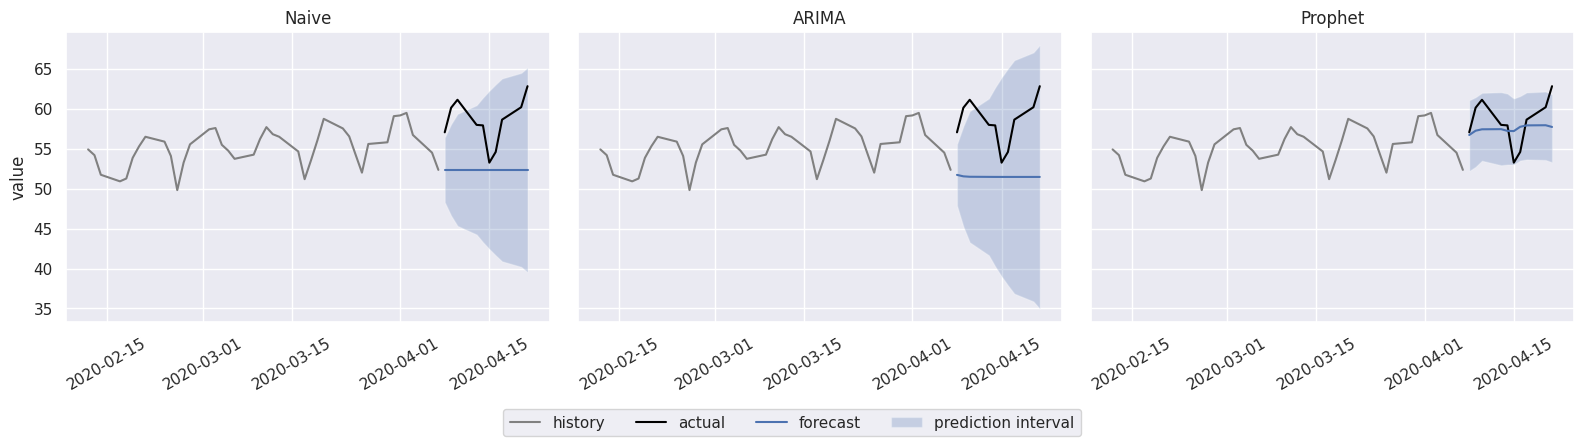

In [30]:
# Plot the three forecasts on a shared y axis.
utils.plot_forecasts(train, test, forecasts, num_history=40, ylabel="value")

**Guided usage**
- Compare the band width across the three panels
  - Observe ARIMA's band widen quickly, since it differences the series
- Compare where the test values fall relative to each band
  - Observe whether the true values stay inside the 95% band

**Implementation** `plot_forecasts(train, test, forecasts, *, num_history=120,
ylabel="Close price ($)")`
- Draws the last `num_history` training points in each panel
- Draws the test values and each model's forecast with its band
- Shares the y axis so the panels are comparable

In [31]:
# Link the function to its source and list its interface.
hintros.print_obj_info(utils.plot_forecasts)

- `plot_forecasts(train: pandas.core.series.Series, test: pandas.core.series.Series, forecasts: Dict[str, pandas.core.frame.DataFrame], *, num_history: int = 120, ylabel: str = 'Close price ($)', figsize: Tuple[float, float] = (16, 4.5)) -> None`  
  Plot history, actual test values, and each forecast with its interval.

https://github.com/madhur2003/msml610_fall2026_kats_stock_price_forecasting/blob/UmdTask851_MSML610_Fall2026_Kats_Stock_Price_Forecasting/class_project/msml610/Fall2026/projects/UmdTask851_MSML610_Fall2026_Kats_Stock_Price_Forecasting/kats_utils.py#L740


# Part 5: Patterns beyond `fit()` and `predict()`

## Cell 5.1: Search spaces for tuning

- Every model class has a static `get_parameter_search_space()`
- It lists the settings worth tuning, in a format that Kats' tuning tools read

In [32]:
# Read the first two entries of the ARIMA search space.
arima_space = ARIMAModel.get_parameter_search_space()
display(pd.DataFrame(arima_space[:2])[["name", "values"]])
# Outcome: `p` and `d` with the integer values to try.

,name,values
0,p,"[1, 2, 3, 4, 5]"
1,d,"[1, 2]"


## Cell 5.2: `MLARModel` takes only params

- `MLARModel` is a LightGBM regressor over lagged values, with calendar and
  Fourier features
- It breaks the pattern in three ways
  - The model is built from params alone, and the data goes to `train()`
  - The method is `train()`, not `fit()`
  - `predict()` returns a dictionary of frames, one per series

In [33]:
# Predict 10 steps ahead from the last 10 values of the series.
mlar_params = MLARParams(
    target_variable="value", horizon=10, input_window=10, freq="B"
)
mlar_model = MLARModel(mlar_params)
print("type(mlar_model)=", type(mlar_model))
# Outcome: a model that holds the settings and no data.

type(mlar_model)= <class 'kats.models.ml_ar.MLARModel'>


## Cell 5.3: `train()` takes a list of series

In [34]:
# Train on the training set, passed as a list of one series.
with utils.quiet_model_logs():
    mlar_model.train([train_ts])
print("trained on", len(train_ts), "points")
# Outcome: no output, the model keeps its state inside.

trained on 70 points


## Cell 5.4: `predict()` returns a dictionary

In [35]:
# Forecast the horizon that was set in the params.
with utils.quiet_model_logs():
    mlar_output = mlar_model.predict()
print("type(mlar_output)=", type(mlar_output))
print("keys=", list(mlar_output.keys()))
# Outcome: a dictionary with one key, since there is a single series.

type(mlar_output)= <class 'dict'>
keys= [0]


In [36]:
# Look at the frame of the only series.
mlar_forecast = mlar_output[0]
display(mlar_forecast.head(3))
# Outcome: the forecast sits in the `forecast` column, with no band.

,time,dummy,variable,forecast
0,2020-04-08,0,value,59.383713
1,2020-04-09,0,value,60.337749
2,2020-04-10,0,value,60.540385


## Cell 5.5: Bring it into the common format

In [37]:
# Rename to the common column names so it can be compared with the others.
mlar_common = mlar_forecast.rename(columns={"forecast": "fcst"})[
    ["time", "fcst"]
]
mlar_mae = utils.compute_mae(test.to_numpy(), mlar_common["fcst"].to_numpy())
print("MLAR MAE=", round(mlar_mae, 3))
# Outcome: an error in the same units as the series, comparable to Cell 4.3.

MLAR MAE= 1.404


# Part 6: Interactive exploration

## Cell 6.1: What happens to ARIMA when the order changes?

- Change `order` and rerun the cell
- Try `(0, 1, 0)`, `(1, 1, 1)`, and `(2, 1, 0)`
- Ask which order has the lowest MAE, and whether it is also the one with the
  lowest AIC from `utils.select_arima_order()`

In [38]:
# Edit the order and rerun.
order = (1, 1, 0)
experiment_forecast = utils.forecast_arima(train, 10, order=order)
experiment_mae = utils.compute_mae(
    test.to_numpy(), experiment_forecast["fcst"].to_numpy()
)
print("order=", order, "MAE=", round(experiment_mae, 3))
# Outcome: one number per order, to compare across reruns.

order= (1, 1, 0) MAE= 6.868


## Cell 6.2: What happens to Prophet when the seasonality changes?

- Set `weekly` to `False` and rerun
- Ask what the weekly pattern does on a series with no weekend rows

In [39]:
# Edit the flag and rerun.
weekly = True
experiment_prophet = utils.forecast_prophet(
    train, 10, yearly_seasonality=False, weekly_seasonality=weekly
)
experiment_prophet_mae = utils.compute_mae(
    test.to_numpy(), experiment_prophet["fcst"].to_numpy()
)
print("weekly=", weekly, "MAE=", round(experiment_prophet_mae, 3))
# Outcome: one number per setting, to compare across reruns.

weekly= True MAE= 2.331


## Summary: The Mental Model

- `TimeSeriesData` is the only input type: a `time` column and a `value` column,
  sliced like a list and converted back with `to_dataframe()`
- Every forecaster is built from a `Params` object and a `Model` object, trained
  in place with `fit()`, and asked for a `DataFrame` with `predict(steps, freq)`
- The forecast has the columns `time`, `fcst`, `fcst_lower`, and `fcst_upper`,
  so ARIMA and Prophet can be compared with the same code
- The defaults are not aligned: ARIMA's band is 95% and ignores `alpha`, and
  Prophet's is 80%, so set `interval_width` or use the wrappers before comparing
- `MLARModel` follows a different pattern (`train()` and a dictionary output),
  so check the interface of each model before assuming `fit()` and `predict()`